## 1. Import Libraries

Let's start by importing the necessary libraries for our model analysis. We will use TensorFlow to load the model, Matplotlib and Seaborn for visualizations, and Scikit-Learn for computing the performance metrics.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow Version: {tf.__version__}")


TensorFlow Version: 2.21.0


## 2. Load Test Data

Now we load the preprocessed test data (`X_test` and `y_test`). This is the data that the model hasn't seen during training, ensuring a fair evaluation.

In [2]:
data_path = "../dataset/preprocessed_data.npz"

if not os.path.exists(data_path):
    data_path = "dataset/preprocessed_data.npz"

data = np.load(data_path)

X_test = data["X_test"]
y_test = data["y_test"]

print(f"Test data loaded! Shape of X_test: {X_test.shape}, y_test: {y_test.shape}")


Test data loaded! Shape of X_test: (12309, 80, 80, 1), y_test: (12309,)


## 3. Load Trained CNN

Next, we load the trained Convolutional Neural Network (CNN) model from the saved `.keras` file.

In [3]:
model_path = "../models/drowsiness_cnn_model.keras"

model = tf.keras.models.load_model(model_path)
print("Model loaded successfully!")
model.summary()


Model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 78, 78, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 39, 39, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 37, 37, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 18, 18, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │         524,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,851,269 (7.06 MB)

 Trainable params: 617,089 (2.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,234,180 (4.71 MB)

## 4. Generate Predictions

We will now use the trained model to generate predictions on our test set. Since this is a binary classification task, we extract the probabilities and convert them into binary labels (0 for Closed, 1 for Open) using a threshold of 0.5.

In [4]:
# Generate probabilities
y_pred_probs = model.predict(X_test)

# Convert probabilities to binary labels (threshold = 0.5)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

print(f"Generated {len(y_pred)} predictions.")


385/385 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step
Generated 12309 predictions.


In [11]:


# Get predictions from the trained model
y_prob = model.predict(X_test, verbose=0).ravel()

# Convert probabilities into class labels
y_pred = (y_prob >= 0.5).astype(int)

# Find incorrect predictions
incorrect_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Incorrect predictions:", len(incorrect_indices))
print("Correct predictions:", len(y_test) - len(incorrect_indices))
print("Error rate:", round(len(incorrect_indices) / len(y_test) * 100, 2), "%")

Total test images: 12309
Incorrect predictions: 1523
Correct predictions: 10786
Error rate: 12.37 %


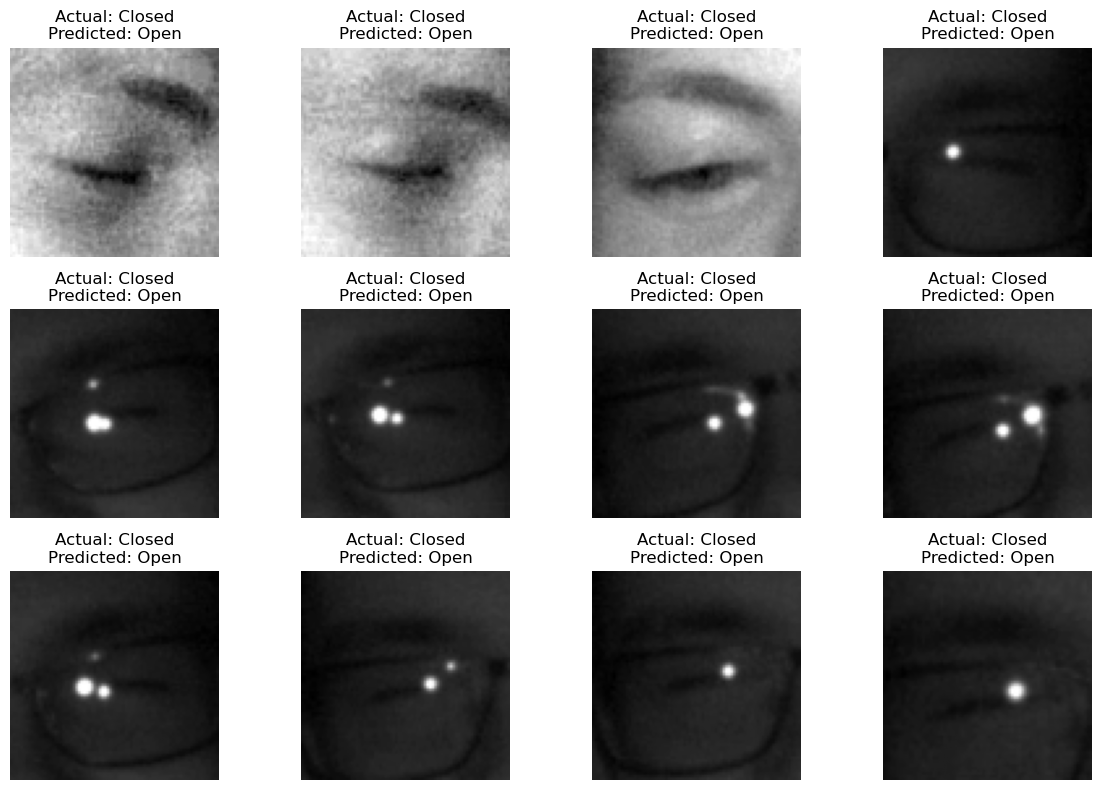

In [18]:

# Display up to 12 incorrect predictions
n = min(12, len(incorrect_indices))

plt.figure(figsize=(12, 8))

for i in range(n):
    idx = incorrect_indices[i]

    actual = "Closed" if y_test[idx] == 0 else "Open"
    predicted = "Closed" if y_pred[idx] == 0 else "Open"

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# Actual closed, predicted open
missed_closed = np.where(
    (y_test == 0) & (y_pred == 1)
)[0]

# Actual open, predicted closed
missed_open = np.where(
    (y_test == 1) & (y_pred == 0)
)[0]

print("Closed eyes predicted as open:", len(missed_closed))
print("Open eyes predicted as closed:", len(missed_open))

Closed eyes predicted as open: 1338
Open eyes predicted as closed: 185


In [23]:
X_val = data["X_val"]
y_val = data["y_val"]

In [27]:
from sklearn.metrics import confusion_matrix

# Get test probabilities from the trained model
test_prob = model.predict(X_test, verbose=0).ravel()

print("Test Threshold Analysis")
print("-" * 50)

for threshold in [0.30, 0.40, 0.50,0.35,0.45,0.55,0.60]:

    test_pred = (test_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = (tn + tp) / len(y_test)
    closed_recall = tn / (tn + fp)
    open_recall = tp / (tp + fn)

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Closed-eye recall: {closed_recall * 100:.2f}%")
    print(f"Open-eye recall: {open_recall * 100:.2f}%")
    print(f"Closed predicted as open: {fp}")
    print(f"Open predicted as closed: {fn}")

Test Threshold Analysis
--------------------------------------------------

Threshold: 0.30
Accuracy: 97.26%
Closed-eye recall: 96.24%
Open-eye recall: 98.21%
Closed predicted as open: 237
Open predicted as closed: 120

Threshold: 0.40
Accuracy: 97.30%
Closed-eye recall: 96.69%
Open-eye recall: 97.88%
Closed predicted as open: 209
Open predicted as closed: 142

Threshold: 0.50
Accuracy: 97.28%
Closed-eye recall: 97.18%
Open-eye recall: 97.38%
Closed predicted as open: 178
Open predicted as closed: 176

Threshold: 0.35
Accuracy: 97.30%
Closed-eye recall: 96.45%
Open-eye recall: 98.09%
Closed predicted as open: 224
Open predicted as closed: 128

Threshold: 0.45
Accuracy: 97.26%
Closed-eye recall: 96.92%
Open-eye recall: 97.59%
Closed predicted as open: 194
Open predicted as closed: 162

Threshold: 0.55
Accuracy: 97.20%
Closed-eye recall: 97.34%
Open-eye recall: 97.06%
Closed predicted as open: 168
Open predicted as closed: 197

Threshold: 0.60
Accuracy: 97.17%
Closed-eye recall: 97.53%
O

## 5. Performance Metrics

To evaluate how well our model performs, we will calculate the Test Loss and Accuracy. We will also display a detailed Classification Report containing Precision, Recall, and F1-Score for each class.

In [5]:
# Evaluate test loss and accuracy
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}\n")

# Display classification report
class_names = ["Closed (0)", "Open (1)"]
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))


Test Accuracy: 87.63%
Test Loss: 0.4458

Classification Report:
              precision    recall  f1-score   support

  Closed (0)       0.96      0.78      0.86      6082
    Open (1)       0.82      0.97      0.89      6227

    accuracy                           0.88     12309
   macro avg       0.89      0.88      0.87     12309
weighted avg       0.89      0.88      0.88     12309



## 6. Confusion Matrix

A Confusion Matrix provides a visual summary of our model's performance. It helps us understand where the model gets confused (e.g., predicting 'Open' when the eyes are actually 'Closed').

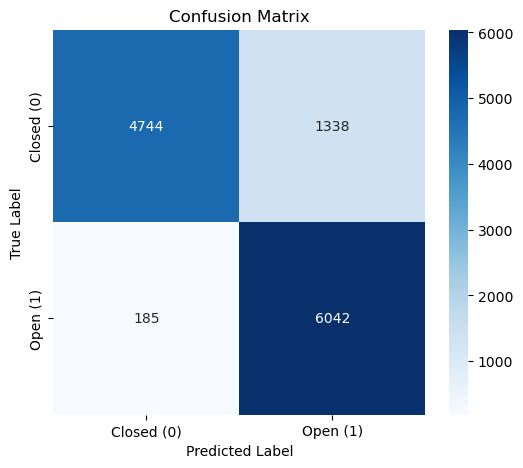

In [6]:
# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using Seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


## 7. Correct Predictions

Let's visualize some samples where the model made **correct** predictions to see what kind of images it successfully classifies.

Total Correct Predictions: 10786


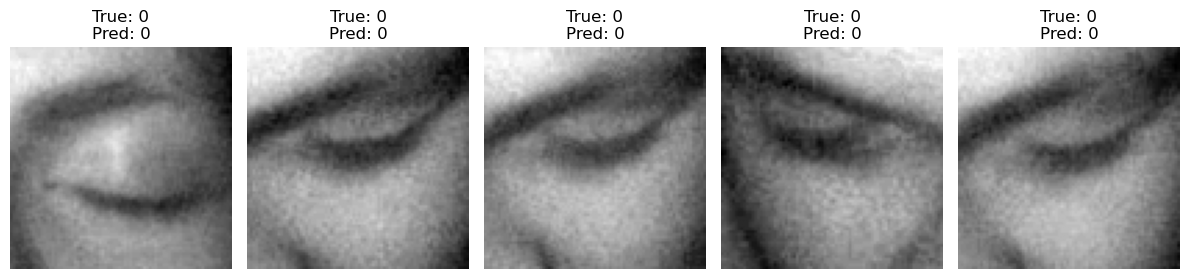

In [7]:
# Find indices of correct predictions
correct_indices = np.where(y_pred == y_test)[0]
print(f"Total Correct Predictions: {len(correct_indices)}")

# Plot some correct predictions
plt.figure(figsize=(12, 4))
for i, idx in enumerate(correct_indices[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 8. Incorrect Predictions

Analyzing **incorrect** predictions is crucial. It helps us understand the model's blind spots and gather insights on how to improve the dataset or the architecture (e.g., lighting conditions, glasses, reflections).

Total Incorrect Predictions: 1523


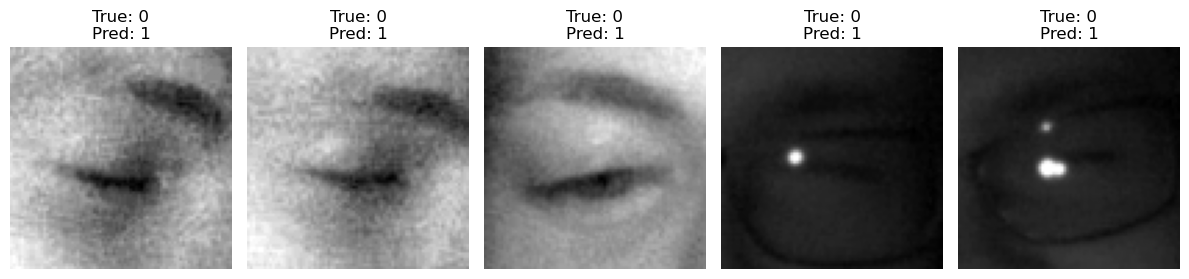

In [8]:
# Find indices of incorrect predictions
incorrect_indices = np.where(y_pred != y_test)[0]
print(f"Total Incorrect Predictions: {len(incorrect_indices)}")

if len(incorrect_indices) > 0:
    plt.figure(figsize=(12, 4))
    for i, idx in enumerate(incorrect_indices[:min(5, len(incorrect_indices))]):
        plt.subplot(1, 5, i + 1)
        plt.imshow(X_test[idx].squeeze(), cmap="gray")
        plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found!")


## 9. Prediction Confidence

It's also interesting to see how confident the model is when making predictions. A histogram of the predicted probabilities can show whether the model is highly certain (values close to 0 or 1) or uncertain (values around 0.5).

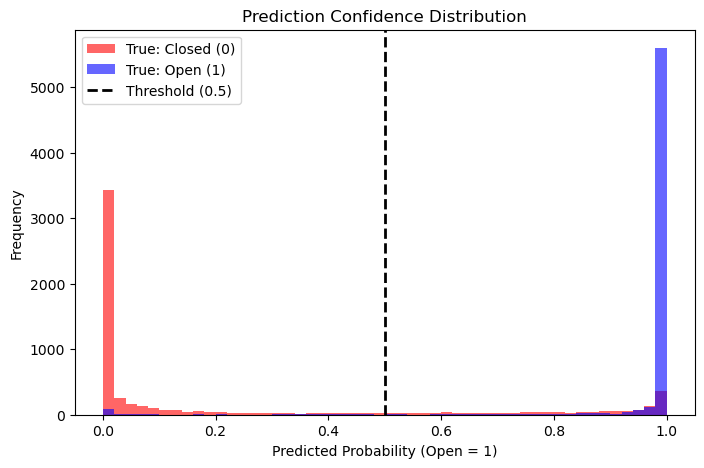

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(y_pred_probs[y_test == 0], bins=50, alpha=0.6, color='red', label='True: Closed (0)')
plt.hist(y_pred_probs[y_test == 1], bins=50, alpha=0.6, color='blue', label='True: Open (1)')
plt.axvline(0.5, color='black', linestyle='dashed', linewidth=2, label='Threshold (0.5)')
plt.xlabel("Predicted Probability (Open = 1)")
plt.ylabel("Frequency")
plt.title("Prediction Confidence Distribution")
plt.legend()
plt.show()


## 10. Final Model Analysis

Based on the above evaluations, we can summarize the strengths and weaknesses of the model. We achieved good accuracy, but inspecting the misclassifications and the confidence distribution gives us a clear idea of where the model might fail in a real-world scenario.

In [10]:
# Summary block
print("Final Analysis Summary")
print("-" * 30)
print(f"Test Accuracy: {test_acc*100:.2f}%")
print("Precision/Recall/F1-Score: See Classification Report")
print(f"Misclassifications: {len(incorrect_indices)} out of {len(y_test)}")
print("-" * 30)
print("Next Steps: Depending on the errors, we might want to augment data (e.g., changes in lighting, angles, glasses) or experiment with different architectures.")



Final Analysis Summary
------------------------------
Test Accuracy: 87.63%
Precision/Recall/F1-Score: See Classification Report
Misclassifications: 1523 out of 12309
------------------------------
Next Steps: Depending on the errors, we might want to augment data (e.g., changes in lighting, angles, glasses) or experiment with different architectures.
